# Figure 6

![Full Figure](../figures/fig06_FULL.png)

## Code for Figure 6A–D: variability in the multinomial advantage over the binary model

**Goal:** Show that the improvement of the filtered-history + interaction multinomial model over the binary model varies across animals, tracks how much a violation disrupts the next decision, and is larger in an animal's lower-violation sessions.

| Panel | Content | Inputs |
|---|---|---|
| A | Per-animal improvement over the binary base, sorted | `scripts/export_fig05_animal_deltas.py` |
| B | Improvement vs post-violation drop in % correct (Fig 4A measure) | `scripts/prepare_fig06_across_animals.py` |
| C | Trained violation rate vs post-violation drop, colored by improvement | `scripts/prepare_fig06_across_animals.py` |
| D | Post-violation drop in each animal's low- vs high-violation sessions | `scripts/prepare_fig06_within_animal.py` |

The post-violation drop is the session-averaged hit rate after a non-violation minus after a violation (percentage points). Analyses are post hoc and correlational; N = 16 animals. Improvement vs trained violation rate and hit rate is reported in the text only (printed with Panel C). The repeat-violation control (printed with Panel C) checks that excluding violation trials from % correct does not produce the smaller drop in high-violation animals.

**Outputs:** `figures/fig06a_animal_improvement.png`, `figures/fig06b_drop_vs_improvement.png`, `figures/fig06c_violation_rate_vs_drop.png`, `figures/fig06d_within_animal_split.png`.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import TwoSlopeNorm

from violations_glm.config import BINARY_MODEL_COMPARE_COLOR
from violations_glm.io import (
    load_fig05_animal_deltas,
    load_fig05_animal_deltas_summary,
    load_fig06_across_animal_statistics,
    load_fig06_animal_table,
    load_fig06_session_split,
    load_fig06_within_animal_statistics,
)
from violations_glm.plotting import (
    colored_animal_scatter,
    configure_publication_dpi,
    save_figure,
)
from violations_glm.stats import animal_level_association, within_subject_test

configure_publication_dpi()
sns.set_context("talk")

In [ ]:
DELTA = "binary_prev_viol_filtered_itrx"
DROP = "post_violation_hit_drop_pp"
DELTA_LABEL = r"$\Delta$ bits/trial vs binary base"
DROP_LABEL = "Post-violation drop in % correct"
VIOLATION_RATE_LABEL = "Trained violation rate (%)"

animals = load_fig06_animal_table()
across_statistics = load_fig06_across_animal_statistics()
within_statistics = load_fig06_within_animal_statistics()

# One diverging scale for improvement over the binary model (blue better, red worse),
# shared by panels A-C and centered at zero.
DELTA_LIMIT = animals[DELTA].abs().max()
DELTA_CMAP = "RdBu"
DELTA_NORM = TwoSlopeNorm(vmin=-DELTA_LIMIT, vcenter=0, vmax=DELTA_LIMIT)

## Panel A — Improvement over the binary model, by animal

Filtered violation history + interaction multinomial model vs the baseline binary model (the Fig 5B comparison), one bar per animal, sorted by improvement. Bars use the same diverging color scale as the points in panels B–C (blue: better than binary; red: worse).

In [ ]:
animal_deltas = load_fig05_animal_deltas().sort_values(
    "bits_per_trial_relative_to_base", ascending=False
)
animal_summary = load_fig05_animal_deltas_summary()

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(
    data=animal_deltas,
    x="animal_id",
    y="bits_per_trial_relative_to_base",
    order=animal_deltas["animal_id"],
    palette=[
        plt.get_cmap(DELTA_CMAP)(DELTA_NORM(value))
        for value in animal_deltas["bits_per_trial_relative_to_base"]
    ],
    ax=ax,
)
ax.axhline(0, color="black", linewidth=0.8)
ax.tick_params(axis="x", rotation=90)
ax.set(xlabel="Animal", ylabel=DELTA_LABEL.replace("trial ", "trial\n"))
sns.despine(ax=ax)
fig.tight_layout()
save_figure(fig, "fig06a_animal_improvement")

print(
    f"{animal_summary['n_improved']} of {animal_summary['n_animals']} animals improve; "
    f"mean {animal_summary['mean_delta']:+.5f} "
    f"(range {animal_summary['min_delta']:+.4f} in {animal_summary['min_animal']} "
    f"to {animal_summary['max_delta']:+.4f} in {animal_summary['max_animal']})"
)

## Panel B — Improvement vs post-violation drop

In [ ]:
drop_statistics = animal_level_association(animals, DROP, DELTA)

fig, ax = plt.subplots(figsize=(6, 6))
colored_animal_scatter(
    ax,
    animals,
    DROP,
    DELTA,
    DELTA,
    drop_statistics,
    cmap=DELTA_CMAP,
    norm=DELTA_NORM,
    stats_corner="upper left",
    annotate_animals=False,
)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set(xlabel=DROP_LABEL, ylabel=DELTA_LABEL)
fig.tight_layout()
save_figure(fig, "fig06b_drop_vs_improvement")

leave_one_out = across_statistics["against_binary_filtered_itrx_delta"][DROP]
print(
    f"Pearson r = {drop_statistics['pearson_r']:.2f}, p = {drop_statistics['pearson_p']:.2g}; "
    f"Spearman rho = {drop_statistics['spearman_r']:.2f}, p = {drop_statistics['spearman_p']:.2g}; "
    f"leave-one-out r = {leave_one_out['loo_r_min']:.2f} to {leave_one_out['loo_r_max']:.2f}"
)

## Panel C — Violation rate vs post-violation drop

Points in B–C share panel A's color scale; the colorbar is shown here only. Improvement vs trained violation rate and vs trained hit rate are reported in the text and printed below (no panel).

**Repeat-violation control.** Violation trials are excluded from % correct, so if a disengaged post-violation trial becomes another violation instead of an error, it drops out of the drop. If this explained the smaller drop in high-violation animals, animals that repeat violations more should show smaller drops. Computed by [`scripts/prepare_fig06_within_animal.py`](../scripts/prepare_fig06_within_animal.py).

In [ ]:
violation_statistics = animal_level_association(animals, "viol_rate", DELTA)
hit_rate_statistics = animal_level_association(animals, "hit_rate", DELTA)
rate_drop_statistics = animal_level_association(animals, "viol_rate", DROP)

fig, ax = plt.subplots(figsize=(7, 6))
points = colored_animal_scatter(
    ax,
    animals,
    "viol_rate",
    DROP,
    DELTA,
    rate_drop_statistics,
    cmap=DELTA_CMAP,
    norm=DELTA_NORM,
    fit_line=False,
    stats_corner="upper right",
    annotate_animals=False,
)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set(xlabel=VIOLATION_RATE_LABEL, ylabel=DROP_LABEL, xlim=(8, 35))
fig.colorbar(points, ax=ax, label=DELTA_LABEL)
fig.tight_layout()
save_figure(fig, "fig06c_violation_rate_vs_drop")

partial = across_statistics["partial"]
partial_rate = partial["delta_vs_viol_rate_given_post_violation_hit_drop"]
partial_drop = partial["delta_vs_post_violation_hit_drop_given_viol_rate"]
print(
    f"Spearman rho = {rate_drop_statistics['spearman_r']:.2f}, "
    f"p = {rate_drop_statistics['spearman_p']:.2g}"
)
print(
    f"Improvement vs violation rate | drop: partial r = {partial_rate['partial_r']:.2f}, "
    f"p = {partial_rate['partial_p']:.2g}"
)
print(
    f"Improvement vs drop | violation rate: partial r = {partial_drop['partial_r']:.2f}, "
    f"p = {partial_drop['partial_p']:.2g}"
)
print("Worse than binary:",
      animals.loc[animals[DELTA] < 0, "animal_id"].tolist())
print("Post-violation drop < 1.5 pp:",
      animals.loc[animals[DROP] < 1.5, "animal_id"].tolist())
violation_leave_one_out = across_statistics["against_binary_filtered_itrx_delta"]["viol_rate"]
print(
    f"Improvement vs violation rate: Pearson r = {violation_statistics['pearson_r']:.2f}, "
    f"p = {violation_statistics['pearson_p']:.2g}; "
    f"Spearman rho = {violation_statistics['spearman_r']:.2f}, "
    f"p = {violation_statistics['spearman_p']:.2g}; "
    f"without W065 and W083: r = {violation_leave_one_out['pearson_r_without_W065_W083']:.2f}, "
    f"p = {violation_leave_one_out['pearson_p_without_W065_W083']:.2g}"
)
print(
    f"Improvement vs hit rate: Pearson r = {hit_rate_statistics['pearson_r']:.2f}, "
    f"p = {hit_rate_statistics['pearson_p']:.2g}"
)
repeat_statistics = within_statistics["drop_vs_repeat_probability"]
repeat_partial = within_statistics["partial_violation_rate_vs_drop_given_repeat_probability"]
rate_repeat_statistics = within_statistics["violation_rate_vs_repeat_probability"]
print(
    f"Drop vs repeat-violation probability: r = {repeat_statistics['pearson_r']:.2f}, "
    f"p = {repeat_statistics['pearson_p']:.2g}"
)
print(
    f"Violation rate vs drop | repeat-violation probability: "
    f"partial r = {repeat_partial['partial_r']:.2f}, p = {repeat_partial['partial_p']:.2g} "
    f"(violation rate vs repeat probability r = {rate_repeat_statistics['pearson_r']:.2f})"
)

## Panel D — Post-violation drop in low- vs high-violation sessions

Each animal's trained sessions are split at its median session violation rate. Post hoc and exploratory; computed by [`scripts/prepare_fig06_within_animal.py`](../scripts/prepare_fig06_within_animal.py), which also reports pooled-trial and top-vs-bottom-third robustness checks.

              mean_viol_rate  baseline_hit_rate
session_type                                   
High                    21.6               81.1
Low                     13.2               82.3
16 subjects/replicates:
 • Low-violation sessions: mean = 4.076, SD = 2.510
 • High-violation sessions: mean = 2.949, SD = 2.162

Shapiro–Wilk: W = 0.922, p = 0.183
Paired t-test: t = -4.839170190415344, p = 0.00021661203523694938
median_split: low 4.08 vs high 2.95 pp, p = 0.00022, larger in low for 15 of 16
median_split_pooled: low 3.80 vs high 2.96 pp, p = 0.0008, larger in low for 13 of 16
tertile_split: low 4.04 vs high 2.80 pp, p = 0.0033, larger in low for 14 of 16
tertile_split_pooled: low 3.75 vs high 2.86 pp, p = 0.039, larger in low for 12 of 16


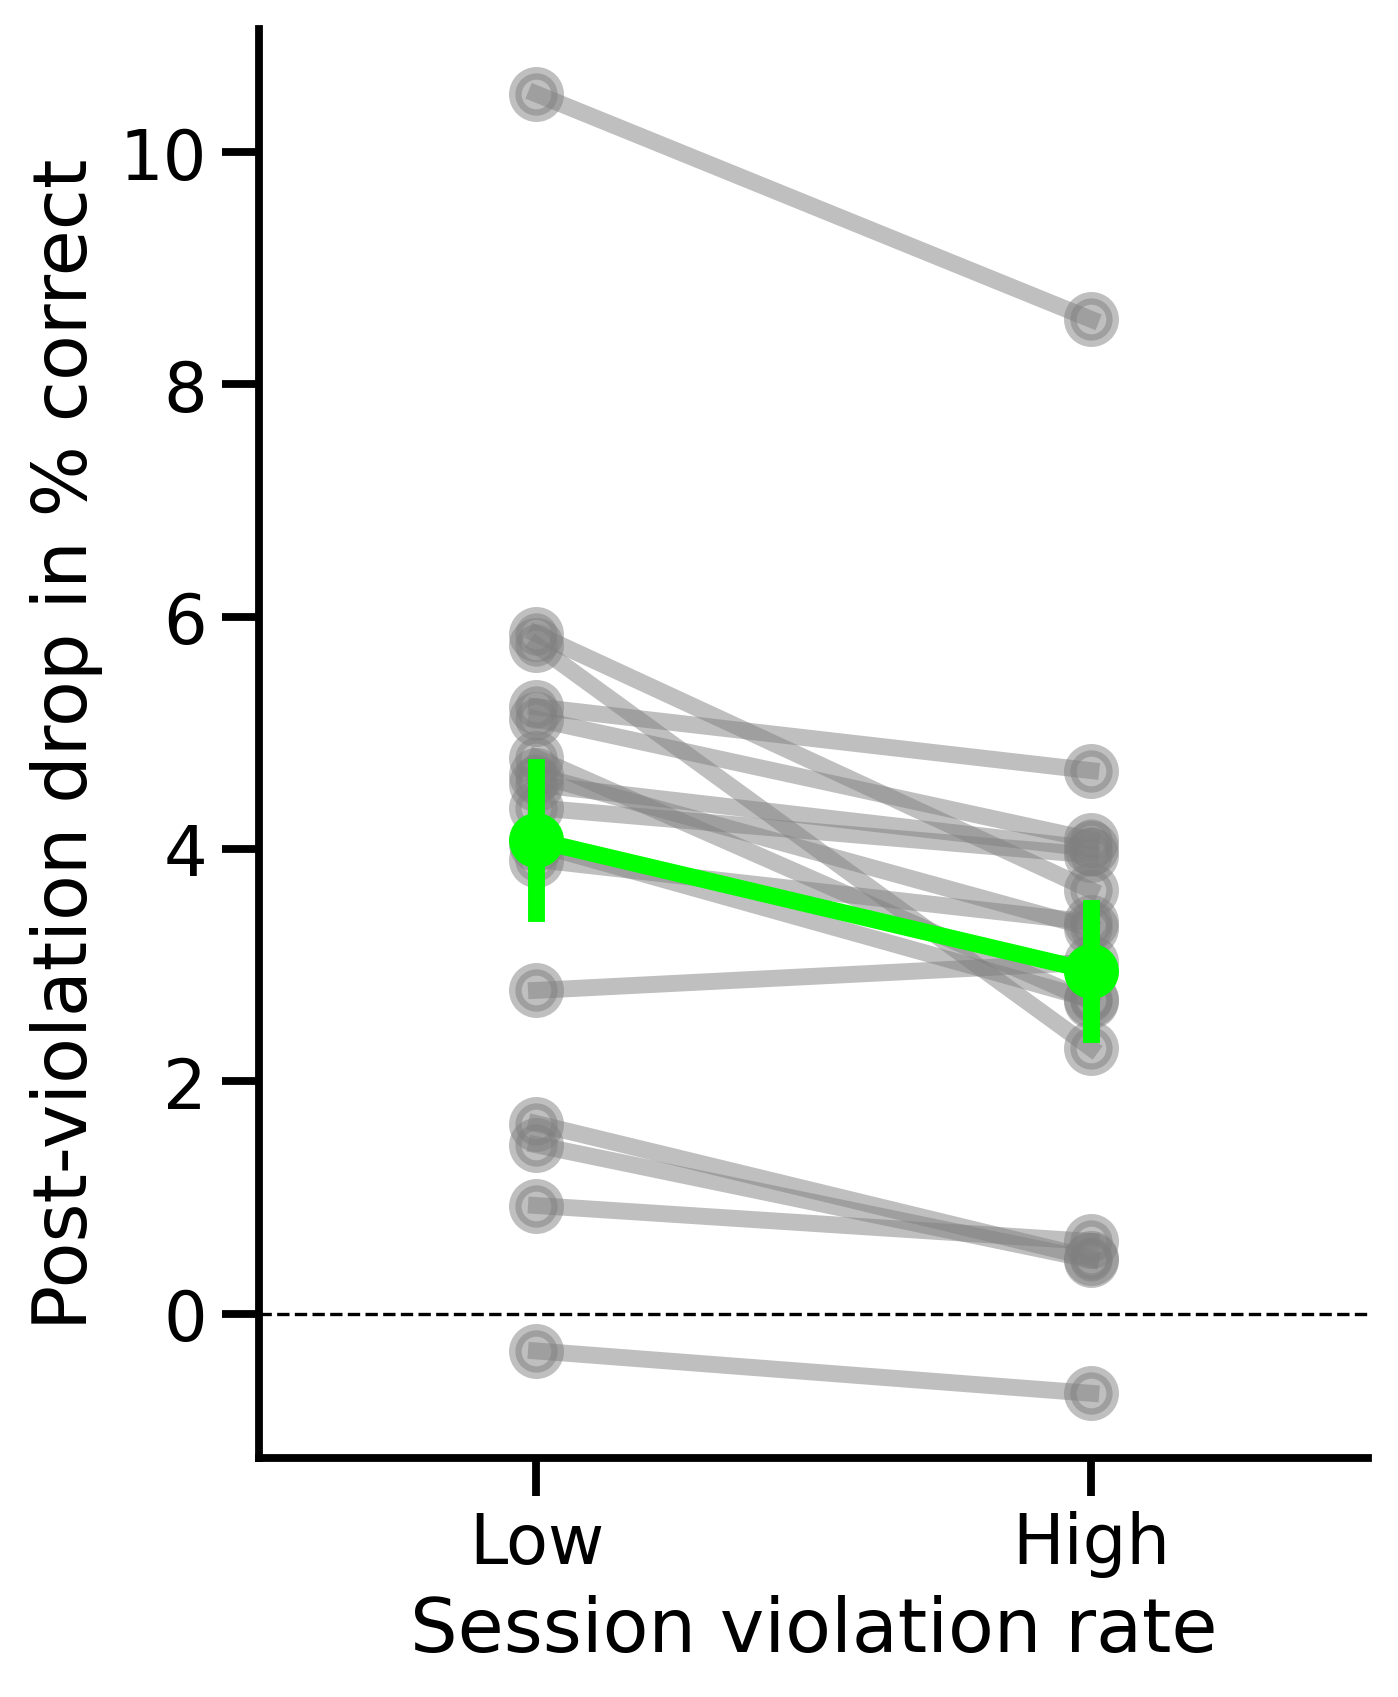

In [15]:
from violations_glm.config import HIT_COLOR


split = load_fig06_session_split()
split["session_type"] = split["half"].map({0.0: "Low", 1.0: "High"})

fig, ax = plt.subplots(figsize=(5, 6))
sns.despine(ax=ax)
sns.pointplot(
    data=split,
    x="session_type",
    y="drop_pp",
    hue="animal_id",
    order=["Low", "High"],
    palette=["gray"] * split["animal_id"].nunique(),
    alpha=0.5,
    ax=ax,
)
sns.pointplot(
    data=split,
    x="session_type",
    y="drop_pp",
    order=["Low", "High"],
    color=HIT_COLOR,
    errorbar="se",
    ax=ax,
)
ax.legend().remove()
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set(xlabel="Session violation rate", ylabel=DROP_LABEL)
fig.tight_layout()
save_figure(fig, "fig06d_within_animal_split")

print(split.groupby("session_type")[
      ["mean_viol_rate", "baseline_hit_rate"]].mean().round(1))
within_subject_test(
    split,
    subject_col="animal_id",
    condition_col="half",
    value_col="drop_pp",
    condition_labels={0.0: "Low-violation sessions",
                      1.0: "High-violation sessions"},
)
for check in ("median_split", "median_split_pooled", "tertile_split", "tertile_split_pooled"):
    result = within_statistics[check]
    print(
        f"{check}: low {result['mean_drop_low_pp']:.2f} vs high {result['mean_drop_high_pp']:.2f} pp, "
        f"p = {result['p']:.2g}, larger in low for {result['n_animals_larger_drop_in_low']} of {result['n_animals']}"
    )